# Clustering Environmental Sounds with Fourier Spectrograms (ESC-50)

In [1]:
import os
import zipfile
from urllib.request import urlretrieve

import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

## 1. Load the ESC-50 dataset

In [2]:
url = 'https://github.com/karoldvl/ESC-50/archive/master.zip'
zip_file_path = 'ESC-50-master.zip'
download_path = './ESC-50-master/'

if not os.path.exists(download_path):
  urlretrieve(url, zip_file_path)
  with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(download_path)
  os.remove(zip_file_path)

DATA_DIR = os.path.join(download_path, 'ESC-50-master')
print(os.listdir(DATA_DIR))

['pytest.ini', 'LICENSE', 'requirements.txt', 'tests', 'meta', 'esc50.gif', 'README.md', 'audio', '.gitignore', '.github', '.circleci']


In [3]:
meta = pd.read_csv(os.path.join(DATA_DIR, 'meta', 'esc50.csv'))
meta.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


## 2. Select the 'dog' and 'chirping_birds' sounds

In [5]:
LABELS = ['dog', 'chirping_birds']

sounds = meta.loc[meta['category'].isin(LABELS)].reset_index(drop=True)
sounds['category'].value_counts()

category
dog               40
chirping_birds    40
Name: count, dtype: int64

In [7]:
def load_audio(filename: str) -> tuple[int, np.ndarray]:
  samples, sample_rate = librosa.load(os.path.join(DATA_DIR, 'audio', filename), sr=None)

  return int(sample_rate), samples.astype(np.float64)


audio = [load_audio(filename) for filename in sounds['filename']]
sample_rate = audio[0][0]
waveforms = np.array([samples for _, samples in audio])
true_labels = (sounds['category'] == 'chirping_birds').to_numpy().astype(int)

print('Sample rate:', sample_rate)
print('Waveforms:', waveforms.shape)

Sample rate: 44100
Waveforms: (80, 220500)


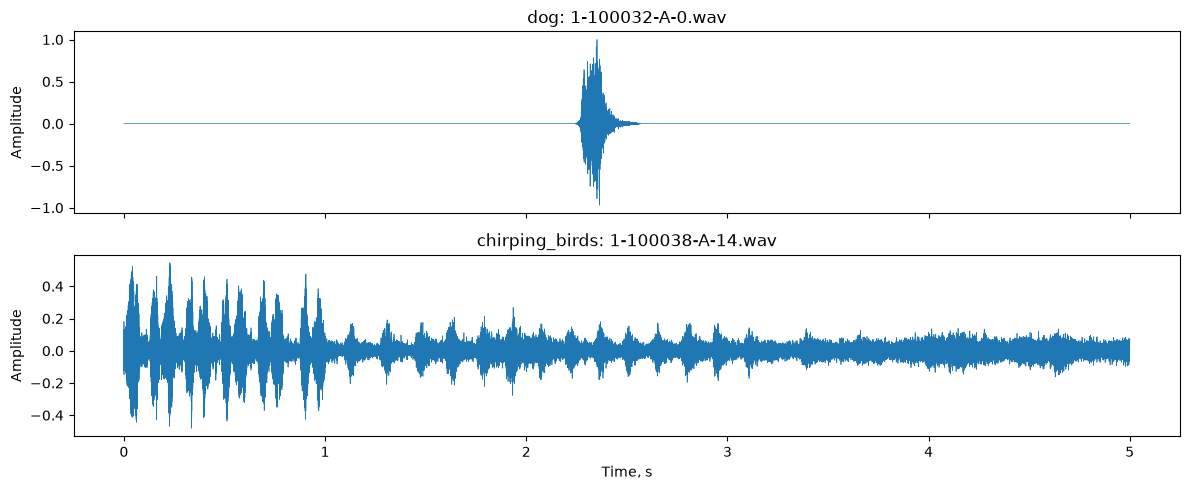

In [10]:
dog_idx = int(np.flatnonzero(true_labels == 0)[0])
bird_idx = int(np.flatnonzero(true_labels == 1)[0])
time_axis = np.arange(waveforms.shape[1]) / sample_rate

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for ax, idx, title in zip(axes, [dog_idx, bird_idx], LABELS):
  ax.plot(time_axis, waveforms[idx], linewidth=0.5)
  ax.set_title(f'{title}: {sounds.loc[idx, "filename"]}')
  ax.set_ylabel('Amplitude')

axes[-1].set_xlabel('Time, s')
plt.tight_layout()
plt.show()

## 3. Spectrogram

In [14]:
def spectrogram(
  samples: np.ndarray,
  sample_rate: int,
  stride_ms: float = 10.0,
  window_ms: float = 20.0,
  max_freq: float | None = None,
  eps: float = 1e-14,
) -> np.ndarray:
  stride_size = int(0.001 * sample_rate * stride_ms)
  window_size = int(0.001 * sample_rate * window_ms)

  truncate_size = (len(samples) - window_size) % stride_size
  samples = samples[:len(samples) - truncate_size]
  nshape = (window_size, (len(samples) - window_size) // stride_size + 1)
  nstrides = (samples.strides[0], samples.strides[0] * stride_size)
  windows = np.lib.stride_tricks.as_strided(samples, shape=nshape, strides=nstrides)

  weighting = np.hanning(window_size)[:, None]
  fft = np.fft.rfft(windows * weighting, axis=0)
  fft = np.absolute(fft) ** 2

  scale = np.sum(weighting**2) * sample_rate
  fft[1:-1, :] *= 2.0 / scale
  fft[(0, -1), :] /= scale

  freqs = float(sample_rate) / window_size * np.arange(fft.shape[0])
  if max_freq is None:
    max_freq = sample_rate / 2
  ind = np.where(freqs <= max_freq)[0][-1] + 1

  return np.log(fft[:ind, :] + eps)

In [15]:
spectrograms = np.array([spectrogram(samples, sample_rate) for samples in waveforms])
print('Spectrograms:', spectrograms.shape)

Spectrograms: (80, 442, 499)


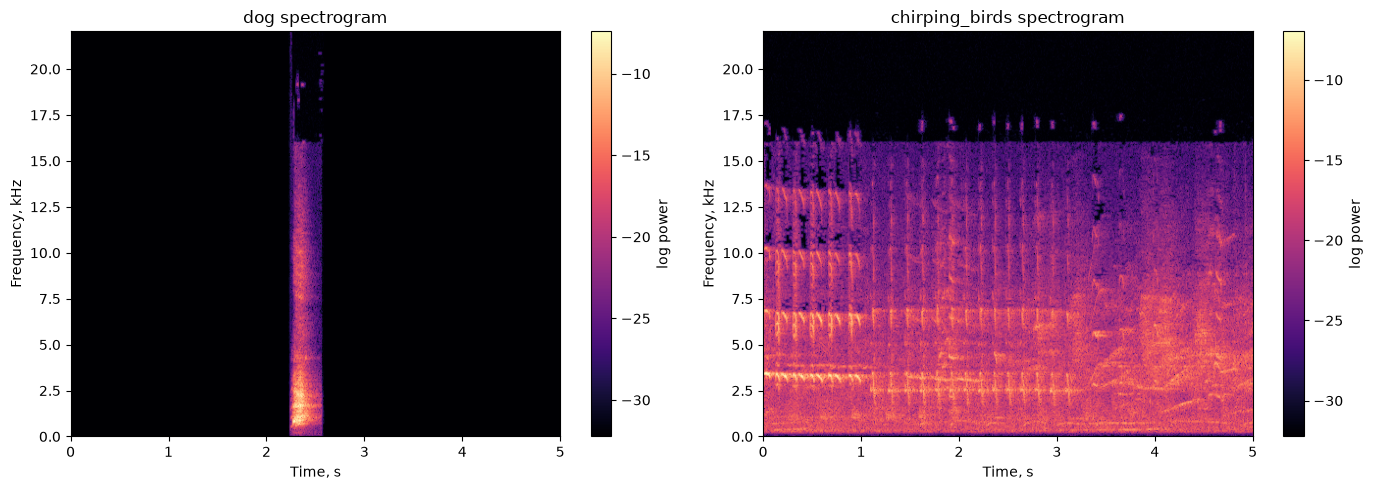

In [21]:
max_freq_khz = sample_rate / 2 / 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, idx, title in zip(axes, [dog_idx, bird_idx], LABELS):
  image = ax.imshow(
    spectrograms[idx],
    origin='lower',
    aspect='auto',
    cmap='magma',
    extent=(0, 5, 0, max_freq_khz),
  )
  ax.set_title(f'{title} spectrogram')
  ax.set_xlabel('Time, s')
  ax.set_ylabel('Frequency, kHz')
  fig.colorbar(image, ax=ax, label='log power')

plt.tight_layout()
plt.show()

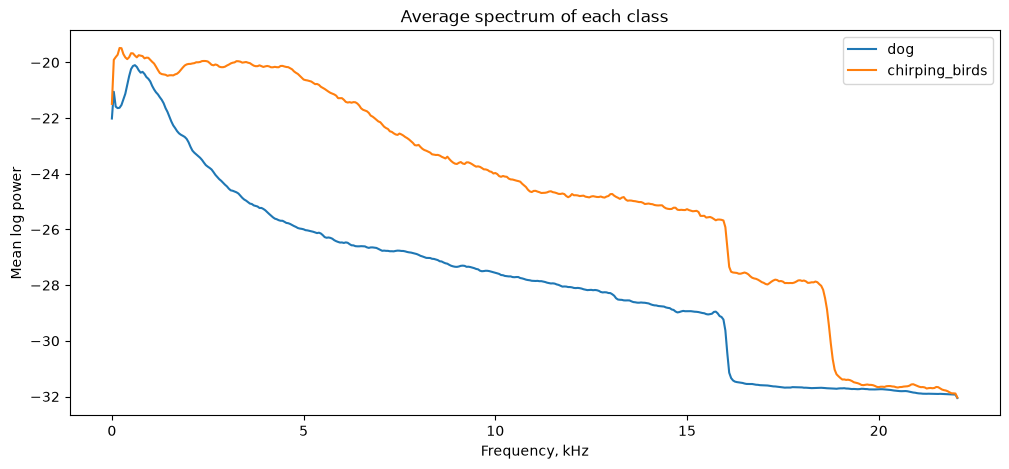

In [24]:
freqs_khz = np.linspace(0, max_freq_khz, spectrograms.shape[1])

fig, ax = plt.subplots(figsize=(12, 5))
for label_id, title in enumerate(LABELS):
  mean_profile = spectrograms[true_labels == label_id].mean(axis=(0, 2))
  ax.plot(freqs_khz, mean_profile, label=title)

ax.set_xlabel('Frequency, kHz')
ax.set_ylabel('Mean log power')
ax.set_title('Average spectrum of each class')
ax.legend()
plt.show()

## 4. Pooling

In [26]:
def pooling_audio(mat: np.ndarray, ksize: tuple[int, int], method: str = 'max', pad: bool = False) -> np.ndarray:
  m, n = mat.shape[:2]
  ky, kx = ksize

  if pad:
    ny, nx = int(np.ceil(m / ky)), int(np.ceil(n / kx))
    mat_pad = np.full((ny * ky, nx * kx) + mat.shape[2:], np.nan)
    mat_pad[:m, :n, ...] = mat
  else:
    ny, nx = m // ky, n // kx
    mat_pad = mat[:ny * ky, :nx * kx, ...]

  blocks = mat_pad.reshape((ny, ky, nx, kx) + mat.shape[2:])
  if method == 'max':
    return np.nanmax(blocks, axis=(1, 3))

  return np.nanmean(blocks, axis=(1, 3))


print(pooling_audio(np.array([[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12], [1, 0, 5, 7]]), (2, 2)))

[[ 6  8]
 [10 12]]


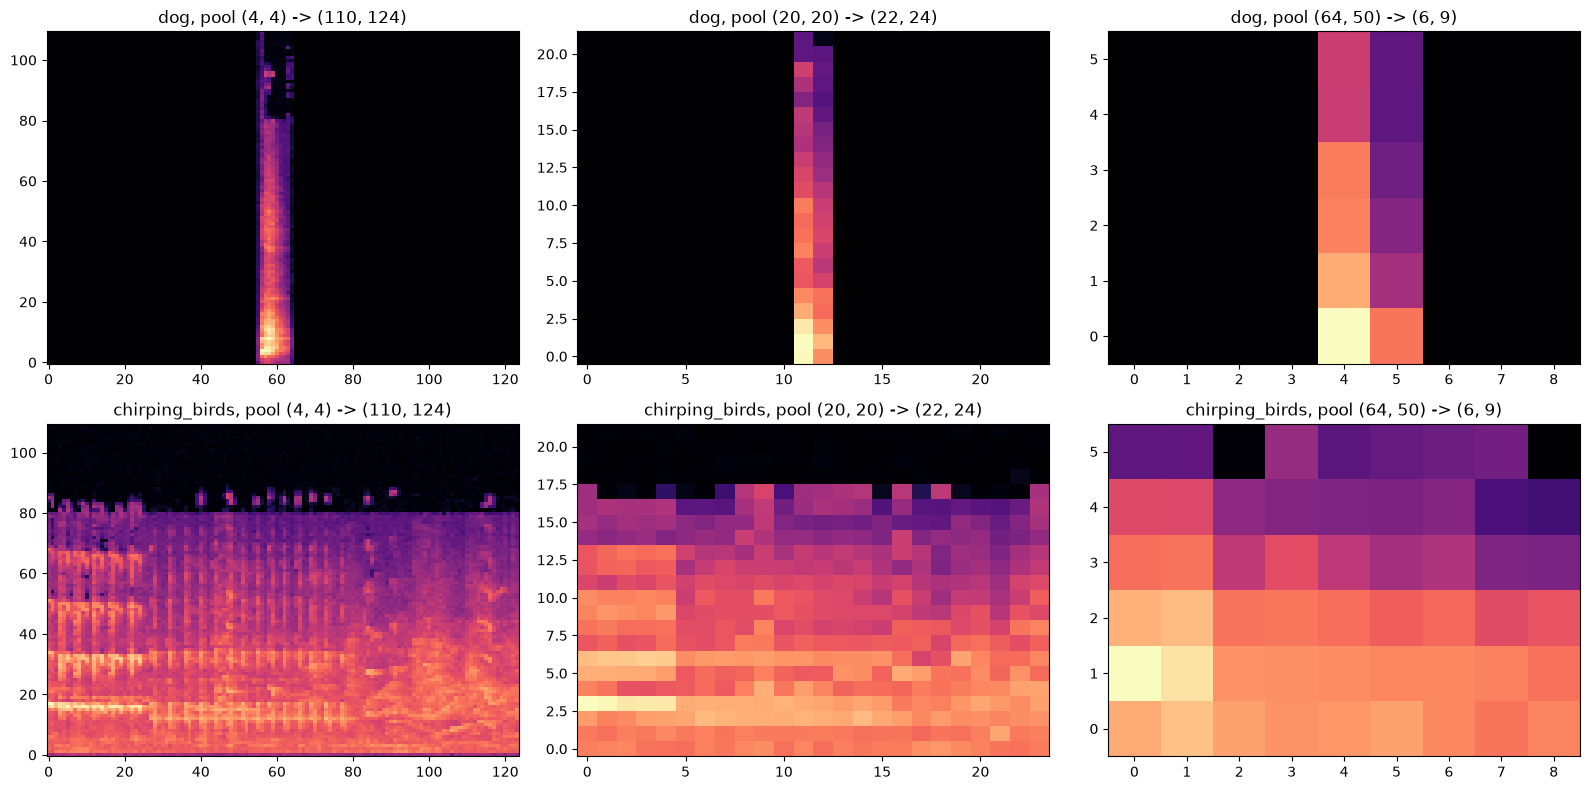

In [31]:
pool_sizes = [(4, 4), (20, 20), (64, 50)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, idx in enumerate([dog_idx, bird_idx]):
  for col, size in enumerate(pool_sizes):
    pooled = pooling_audio(spectrograms[idx], size)
    axes[row, col].imshow(pooled, origin='lower', aspect='auto', cmap='magma')
    axes[row, col].set_title(f'{LABELS[row]}, pool {size} -> {pooled.shape}')

plt.tight_layout()
plt.show()

## 5. Flatten the spectrograms into feature vectors

In [33]:
POOL_SIZE = (20, 20)
POOL_METHOD = 'max'

features = np.array([pooling_audio(spec, POOL_SIZE, POOL_METHOD).flatten() for spec in spectrograms])
print('Original spectrogram size:', spectrograms[0].size)
print('Feature vector length:', features.shape[1])
print(f'Compression: {spectrograms[0].size / features.shape[1]:.0f}x')

Original spectrogram size: 220558
Feature vector length: 528
Compression: 418x


## 6. Spectral clustering

In [40]:
def cluster(features: np.ndarray, scale: bool = False) -> np.ndarray:
  if scale:
    features = StandardScaler().fit_transform(features)
  model = SpectralClustering(
    n_clusters=2,
    affinity='nearest_neighbors',
    n_neighbors=10,
    assign_labels='kmeans',
    random_state=42,
  )

  return model.fit_predict(features)


def align_labels(true_labels: np.ndarray, clusters: np.ndarray) -> np.ndarray:
  if (clusters == true_labels).mean() < 0.5:
    return 1 - clusters

  return clusters


clusters = align_labels(true_labels, cluster(features))
accuracy = (clusters == true_labels).mean()

print(f'Accuracy after label alignment: {accuracy:.2%}')
print(f'Adjusted Rand index: {adjusted_rand_score(true_labels, clusters):.3f}')

Accuracy after label alignment: 75.00%
Adjusted Rand index: 0.240


## 7. Analyze the clusters

In [41]:
pd.crosstab(
  sounds['category'],
  pd.Series(clusters, name='cluster'),
)

cluster,0,1
category,,
chirping_birds,10,30
dog,30,10


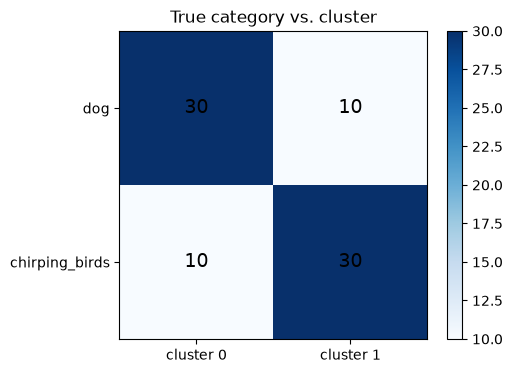

In [45]:
cm = confusion_matrix(true_labels, clusters)

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap='Blues')
for i in range(2):
  for j in range(2):
    ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=14)
ax.set_xticks([0, 1], ['cluster 0', 'cluster 1'])
ax.set_yticks([0, 1], LABELS)
ax.set_title('True category vs. cluster')
fig.colorbar(image, ax=ax)
plt.show()

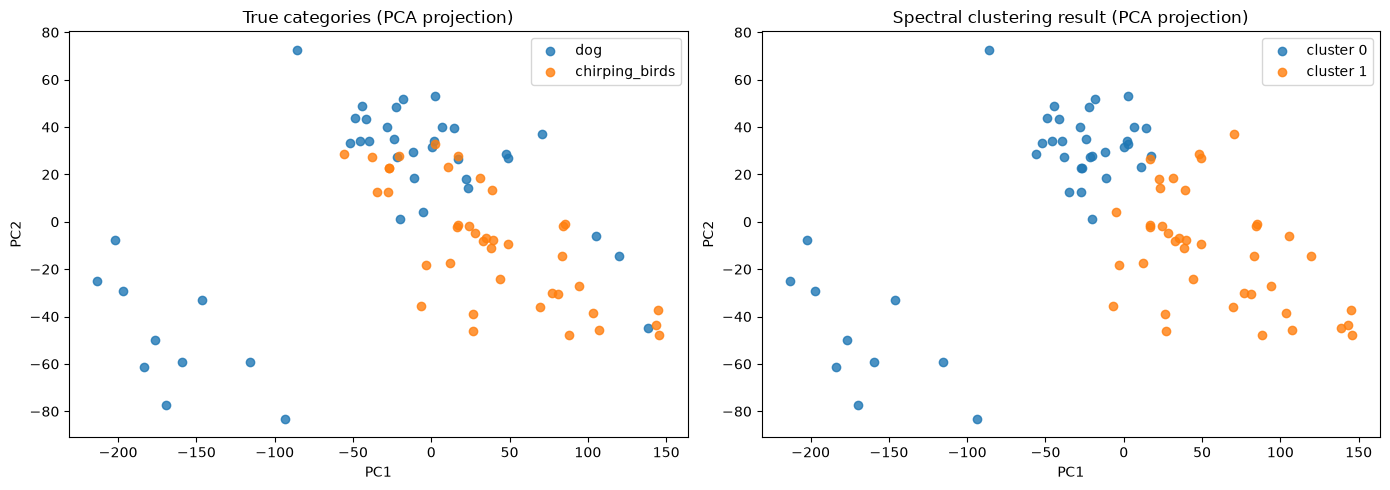

In [50]:
projection = PCA(n_components=2).fit_transform(features)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label_id, title in enumerate(LABELS):
  mask = true_labels == label_id
  axes[0].scatter(projection[mask, 0], projection[mask, 1], label=title, alpha=0.8)
for cluster_id in range(2):
  mask = clusters == cluster_id
  axes[1].scatter(projection[mask, 0], projection[mask, 1], label=f'cluster {cluster_id}', alpha=0.8)

axes[0].set_title('True categories (PCA projection)')
axes[1].set_title('Spectral clustering result (PCA projection)')
for ax in axes:
  ax.set_xlabel('PC1')
  ax.set_ylabel('PC2')
  ax.legend()
plt.tight_layout()
plt.show()

In [52]:
misclustered = sounds.loc[clusters != true_labels, ['filename', 'category']]
misclustered.assign(cluster=clusters[clusters != true_labels])

,filename,category,cluster
5,1-32318-A-0.wav,dog,1
12,1-54918-B-14.wav,chirping_birds,0
20,2-114587-A-0.wav,dog,1
21,2-116400-A-0.wav,dog,1
22,2-117271-A-0.wav,dog,1
27,2-122616-A-14.wav,chirping_birds,0
29,2-72547-B-14.wav,chirping_birds,0
31,2-72547-D-14.wav,chirping_birds,0
32,3-136288-A-0.wav,dog,1
33,3-144028-A-0.wav,dog,1


## 8. Experiments with different pooling (compression) levels

In [70]:
experiment_sizes = [(2, 2), (4, 4), (8, 8), (16, 16), (20, 20), (32, 32), (64, 50), (8, 499), (32, 499)]
experiment_rows = []

for size in experiment_sizes:
  for method_name in ['mean', 'max']:
    pooled = np.array([pooling_audio(spec, size, method_name).flatten() for spec in spectrograms])
    for scale in [False, True]:
      predicted = align_labels(true_labels, cluster(pooled, scale))
      experiment_rows.append({
        'pool size': str(size),
        'pooling': method_name,
        'standardized': scale,
        'features': pooled.shape[1],
        'compression': round(spectrograms[0].size / pooled.shape[1]),
        'accuracy': (predicted == true_labels).mean(),
        'ARI': adjusted_rand_score(true_labels, predicted),
      })

experiments = pd.DataFrame(experiment_rows)
experiments.round(3)

,pool size,pooling,standardized,features,compression,accuracy,ARI
0,"(2, 2)",mean,False,55029,4,0.825,0.415
1,"(2, 2)",mean,True,55029,4,0.788,0.322
2,"(2, 2)",max,False,55029,4,0.650,0.084
3,"(2, 2)",max,True,55029,4,0.800,0.352
4,"(4, 4)",mean,False,13640,16,0.812,0.383
5,"(4, 4)",mean,True,13640,16,0.775,0.294
6,"(4, 4)",max,False,13640,16,0.825,0.415
7,"(4, 4)",max,True,13640,16,0.788,0.322
8,"(8, 8)",mean,False,3410,65,0.825,0.415
9,"(8, 8)",mean,True,3410,65,0.825,0.415


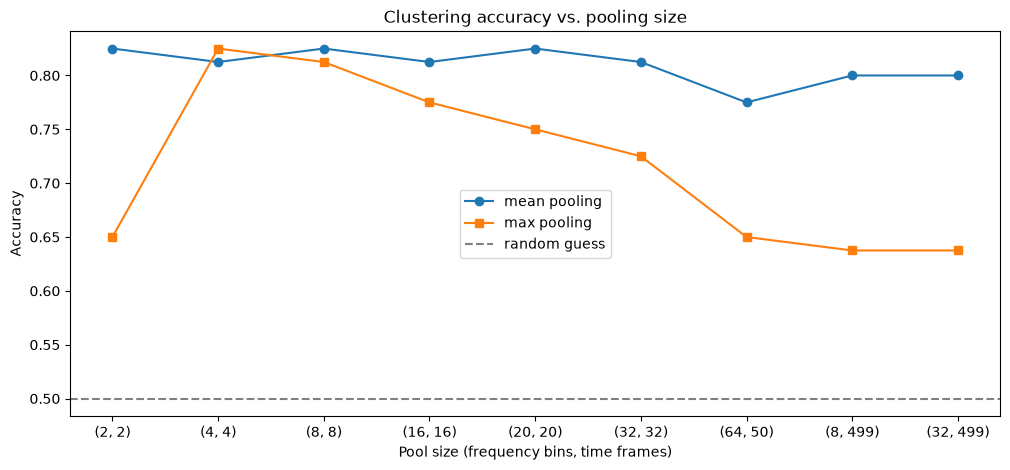

In [76]:
mean_pooling = experiments[(experiments['pooling'] == 'mean') & ~experiments['standardized']]
max_pooling = experiments[(experiments['pooling'] == 'max') & ~experiments['standardized']]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(mean_pooling['pool size'], mean_pooling['accuracy'], marker='o', label='mean pooling')
ax.plot(max_pooling['pool size'], max_pooling['accuracy'], marker='s', label='max pooling')
ax.axhline(0.5, color='gray', linestyle='--', label='random guess')
ax.set_xlabel('Pool size (frequency bins, time frames)')
ax.set_ylabel('Accuracy')
ax.set_title('Clustering accuracy vs. pooling size')
ax.legend()
plt.show()

In [79]:
best_features = np.array([pooling_audio(spec, POOL_SIZE, 'mean').flatten() for spec in spectrograms])
best_clusters = align_labels(true_labels, cluster(best_features))

print(f'Pool {POOL_SIZE}, mean pooling: accuracy = {(best_clusters == true_labels).mean():.2%}, ARI = {adjusted_rand_score(true_labels, best_clusters):.3f}')
pd.crosstab(sounds['category'], pd.Series(best_clusters, name='cluster'))

Pool (20, 20), mean pooling: accuracy = 82.50%, ARI = 0.415


cluster,0,1
category,,
chirping_birds,7,33
dog,33,7


## 9. Baseline without the Fourier transform

In [82]:
baseline_rows = []

for step in [1, 10, 100, 441]:
  raw_features = waveforms.reshape(len(waveforms), -1, step).mean(axis=2)
  predicted = align_labels(true_labels, cluster(raw_features))
  baseline_rows.append({
    'averaging window, samples': step,
    'features': raw_features.shape[1],
    'accuracy': (predicted == true_labels).mean(),
    'ARI': adjusted_rand_score(true_labels, predicted),
  })

pd.DataFrame(baseline_rows).round(3)

,"averaging window, samples",features,accuracy,ARI
0,1,220500,0.512,-0.006
1,10,22050,0.500,-0.013
2,100,2205,0.562,0.013
3,441,500,0.562,0.013


## Conclusion

- 80 clips (40 dog, 40 chirping_birds) were turned into 442 x 499 log-power spectrograms with the lecture's spectrogram() function, reduced with pooling_audio() and flattened into feature vectors.
- With the lecture settings (20 x 20 max pooling, 528 features, 418x compression) spectral clustering puts 30/40 dogs and 30/40 birds into separate clusters: 75% accuracy, ARI 0.24. With 20 x 20 mean pooling it improves to 33/40 and 33/40: 82.5% accuracy, ARI 0.42. So sounds of different origin mostly land in different clusters.
- The classes differ mainly in frequency content: bird chirps carry much more energy in the 2-15 kHz band, while dog barks are short low-frequency bursts surrounded by silence.
- The misclustered clips are split evenly between the classes (7 dogs and 7 birds with mean pooling), so the errors are not a bias towards one class but clips that look atypical for their category.
- Mean pooling is robust to compression: accuracy stays at 78-82% from 4x up to 17,000x (13 features that keep only the average spectrum).
- Max pooling degrades with larger windows (82% -> 64%), because the maximum of a large block is dominated by single loud peaks instead of the overall energy distribution.
- Without the Fourier transform, clustering the raw waveforms gives 50-56% accuracy, which is no better than a random guess: the time-domain signal is not shift-invariant, while the spectrum is.
- The Fourier transform turns a raw signal into features that describe what a sound is made of, and after pooling they are compact enough for clustering or classification.